# 01 · Exploring the CNC milling cutting-sound dataset

**Goal:** understand what is in the dataset before any modelling: what was recorded, how it is labelled, what chatter looks and sounds like in the data, and what pitfalls a model has to deal with.

| | **IMI** (lab) | **KRPM** (industry) |
|---|---|---|
| Machine | Hurco VM20i, 3-axis vertical mill | Mazak HCN-6000, 4-axis horizontal mill |
| Sessions | 18 experiments (`IMI/Exp*`) | 1 recording |
| Labels | cutting intervals **+ chatter scores from 2 operators** | cutting intervals only |
| Process | end-milling | end-milling, facing, drilling |

Every session contains three **synchronized** mono WAVs (48 kHz, 16-bit):

| sensor | device | location |
|---|---|---|
| 0 | USB microphone | working area (airborne sound) |
| 1 | Internal Sound Sensor (ISS: stethoscope + mic) | on or near the spindle |
| 2 | ISS | machine base |

**Contents**
1. Setup
2. Inventory: sessions, durations, cutting time
3. Cutting paths and the experimental design
4. Chatter labels and operator agreement
5. What chatter looks and sounds like
6. A physics-informed view: tooth-passing harmonics
7. Sensor comparison and data quality (clipping!)
8. Lab vs. industry: IMI vs. KRPM
9. Takeaways for modelling

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
try:
    import mtcut
except ImportError:  # package not installed (`pip install -e .`): use the source tree
    sys.path.insert(0, str(ROOT / "src"))
    import mtcut

from mtcut import CHATTER_LABELS, SAMPLE_RATE, SENSORS, discover_sessions, segment_table, session_table
from mtcut.features import harmonic_energy_ratio, rms_db, tooth_passing_harmonics, welch_psd
from mtcut.labels import cohen_kappa, consensus
from mtcut.viz import LABEL_COLORS, SENSOR_COLORS, plot_session_overview, plot_spectrogram

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

sessions = discover_sessions()
S = {s.name: s for s in sessions}
print(f"{len(sessions)} sessions found under {mtcut.config.DATA_ROOT}")
sessions[:3]

19 sessions found under D:\VinUni\code\Chatter\mt_cutting_dataset


[Session(IMI/Exp0-1, sensors=[0, 1, 2]),
 Session(IMI/Exp0-2, sensors=[0, 1, 2]),
 Session(IMI/Exp0-3, sensors=[0, 1, 2])]

## 2. Inventory: sessions, durations, cutting time

`session_table` gives one row per recording. `cutting_frac` is the share of the recording spent actually cutting. The rest is spindle idle, rapid moves and air cutting.

In [2]:
sess = session_table(sessions)
sess.style.format({"duration_s": "{:.1f}", "cutting_s": "{:.1f}", "cutting_frac": "{:.0%}"}).hide(axis="index")

dataset,session,recorded_at,n_sensors,duration_s,n_paths,cutting_s,cutting_frac,has_video,notes
IMI,Exp0-1,2022-10-14 19:38:27.929380,3,70.0,20,40.8,58%,True,
IMI,Exp0-2,2022-10-14 19:42:57.929380,3,150.0,20,39.7,26%,True,
IMI,Exp0-3,2022-10-14 19:56:37.929380,3,140.0,19,38.2,27%,False,No video clip
IMI,Exp1-1-2,2022-10-30 05:46:15.653070,3,100.0,32,34.4,34%,True,
IMI,Exp1-1-A,2022-10-27 19:40:37.114355,3,100.0,32,36.0,36%,False,No video clip
IMI,Exp1-1-B,2022-10-27 19:59:32.589507,3,100.0,32,35.0,35%,False,No video clip
IMI,Exp1-2,2022-10-30 21:17:08.151265,3,100.0,32,34.5,34%,True,
IMI,Exp1-3,2022-10-30 21:29:28.151265,3,100.0,32,34.3,34%,True,
IMI,Exp1-4,2022-10-30 05:59:10.653070,3,100.0,32,33.2,33%,True,
IMI,Exp1-5,2022-10-30 21:37:23.151265,3,100.0,32,34.6,35%,True,This video is only last 2 paths


,duration_s,cutting_s,n_paths,cutting_frac
dataset,,,,
IMI,2789.80,1032.97,583,0.37
KRPM,130.27,57.51,14,0.44


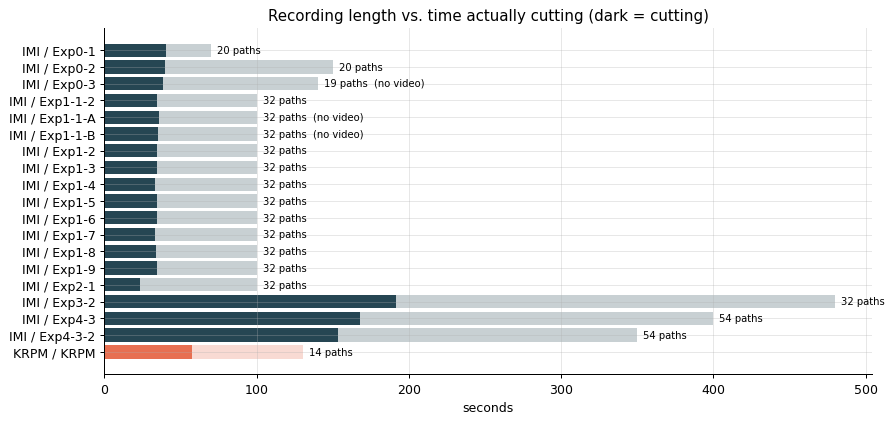

In [3]:
tot = sess.groupby("dataset")[["duration_s", "cutting_s", "n_paths"]].sum()
tot["cutting_frac"] = tot["cutting_s"] / tot["duration_s"]
display(tot.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(sess))
colors = np.where(sess["dataset"] == "IMI", "#264653", "#e76f51")
ax.barh(y, sess["duration_s"], color=colors, alpha=0.25, label="total recording")
ax.barh(y, sess["cutting_s"], color=colors, label="cutting")
for yi, (n, v) in enumerate(zip(sess["n_paths"], sess["has_video"])):
    ax.text(sess["duration_s"].iloc[yi] + 4, yi, f"{n} paths" + ("" if v else "  (no video)"), va="center", fontsize=8)
ax.set_yticks(y, sess["dataset"] + " / " + sess["session"])
ax.invert_yaxis()
ax.set_xlabel("seconds")
ax.set_title("Recording length vs. time actually cutting (dark = cutting)")
plt.show()

**Observations**
* IMI has about **46 min** of audio (x3 sensors), and about 17 min of it is cutting. KRPM has about **2 min**, of which 1 min is cutting. KRPM is roughly 20x smaller than IMI, which is why the second paper frames KRPM as a *scarce target domain* for domain adaptation.
* Only about 35-45% of each recording is cutting. The non-cutting audio (spindle running, rapid moves) is a free source of **"not cutting" examples**.
* The `Exp1-*` sessions all run 100 s with 32 paths each: one standardized parameter sweep repeated at different depths and widths of cut. `Exp3-2`, `Exp4-3` and `Exp4-3-2` are longer runs with a smaller tool.
* The empty `*.txt` files in some folders are notes (their filename is the message). For example, `Exp1-5` says *"This video is only last 2 paths"*.

### Recording format sanity check
The IMI experiments were recorded on different days (14, 27, 28 and 30 Oct 2022) and KRPM on 24 Mar 2022. The timestamp is in each WAV filename. Here we check that the three sensors really are aligned.

In [4]:
from scipy.io import wavfile

rows = []
for s in sessions:
    for k, p in s.wav_paths.items():
        sr, x = wavfile.read(p, mmap=True)
        rows.append({"session": s.id, "sensor": k, "sr": sr, "dtype": str(x.dtype), "n_samples": x.shape[0]})
fmt = pd.DataFrame(rows)
print(fmt.groupby(["sr", "dtype"]).size().rename("files").to_string())
print("\nAll 3 sensors equal length in every session:",
      bool((fmt.groupby("session")["n_samples"].nunique() == 1).all()))
print("Example filenames:", [p.name for p in S["Exp0-1"].wav_paths.values()][:1], [p.name for p in S["KRPM"].wav_paths.values()][:1])

sr     dtype
48000  int16    57

All 3 sensors equal length in every session: True
Example filenames: ['20221014_193827.929380Z_VM20i_sensor0.wav'] ['20220324_131120.455964_Mazak_sound0.wav']


> Note that KRPM names its files `*_Mazak_sound{k}.wav`, while IMI uses `*_VM20i_sensor{k}.wav`. `mtcut.discover_sessions` handles both patterns.

## 3. Cutting paths and the experimental design

A **cutting path** is one pass of the end mill across the workpiece, one row of `cutting.csv`. `segment_table` joins every path with its row in `labeling_all_details.xlsx`, which holds the cutting parameters and both operators' labels.

In [5]:
seg = segment_table(sessions)
seg["chatter"] = consensus(seg["chatter_op1"], seg["chatter_op2"], "max")  # pessimistic merge, see section 4
imi = seg[seg["dataset"] == "IMI"].copy()
krpm = seg[seg["dataset"] == "KRPM"].copy()
print(f"{len(seg)} cutting paths: {len(imi)} IMI + {len(krpm)} KRPM")
seg.sample(5, random_state=0)

597 cutting paths: 583 IMI + 14 KRPM


,segment_id,dataset,session,path_idx,start,end,duration,path_no,machine,tool,tool_setup,tool_condition,workpiece,spindle_rpm,feed_ipm,direction,doc_in,woc_in,chatter_op1,chatter_op2,tool_diameter_in,flutes,tooth_passing_hz,chatter
405,IMI/Exp1-9/026,IMI,Exp1-9,26,83.800,84.975,1.175,27.0,"Hurco, VM20i","1/2"" 5-flute square endmill",Long,Worn,Steel 4140,9000.0,90.0,up,0.5,0.015,1.0,1.0,0.5,5.0,750.000000,1.0
132,IMI/Exp1-1-B/009,IMI,Exp1-1-B,9,29.625,31.300,1.675,10.0,"Hurco, VM20i","1/2"" 5-flute square endmill",Long,New,Steel 4140,5000.0,60.0,down,1.0,0.025,0.0,0.0,0.5,5.0,416.666667,0.0
211,IMI/Exp1-3/024,IMI,Exp1-3,24,76.050,77.725,1.675,25.0,"Hurco, VM20i","1/2"" 5-flute square endmill",Long,Worn,Steel 4140,9000.0,60.0,up,0.5,0.025,1.0,2.0,0.5,5.0,750.000000,2.0
243,IMI/Exp1-4/024,IMI,Exp1-4,24,76.820,78.450,1.630,25.0,"Hurco, VM20i","1/2"" 5-flute square endmill",Long,Worn,Steel 4140,9000.0,60.0,up,1.0,0.020,2.0,1.0,0.5,5.0,750.000000,2.0
85,IMI/Exp1-1-2/026,IMI,Exp1-1-2,26,83.090,84.200,1.110,27.0,"Hurco, VM20i","1/2"" 5-flute square endmill",Long,Worn,Steel 4140,9000.0,90.0,up,1.0,0.025,2.0,2.0,0.5,5.0,750.000000,2.0


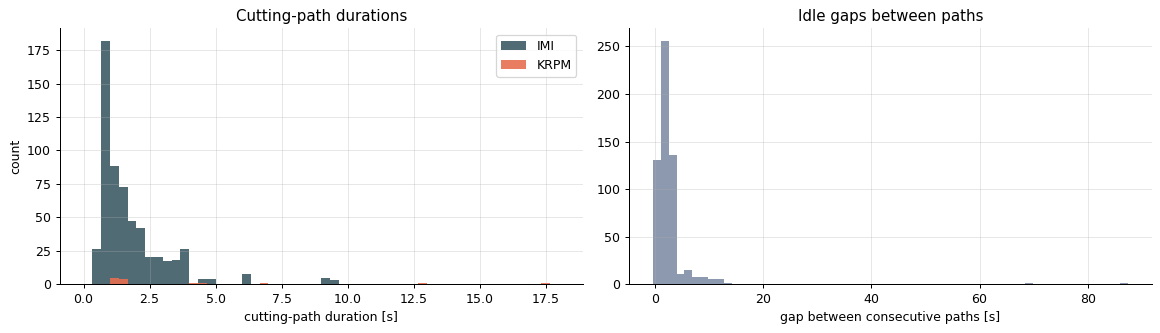

count    583.00
mean       1.77
std        1.41
min        0.58
25%        0.84
50%        1.15
75%        2.06
max        9.34

Negative gaps (overlapping intervals):
   session      0
17  Exp0-1 -0.424


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
bins = np.linspace(0, 18, 55)
axes[0].hist(imi["duration"], bins=bins, color="#264653", alpha=0.8, label="IMI")
axes[0].hist(krpm["duration"], bins=bins, color="#e76f51", alpha=0.9, label="KRPM")
axes[0].set(xlabel="cutting-path duration [s]", ylabel="count", title="Cutting-path durations")
axes[0].legend()

gap = seg.groupby("session", sort=False).apply(lambda g: (g["start"].shift(-1) - g["end"]).dropna()).reset_index(level=0)
axes[1].hist(gap[0], bins=60, color="#8d99ae")
axes[1].set(xlabel="gap between consecutive paths [s]", title="Idle gaps between paths")
plt.tight_layout(); plt.show()

print(imi["duration"].describe().round(2).to_string())
print("\nNegative gaps (overlapping intervals):")
print(gap[gap[0] < 0])

* Most IMI paths are **1-2 s** long. The slow feeds in `Exp3-2` (10-25 IPM) make paths of up to about 9 s. At a 2048-sample window (42.7 ms, the MTConnect chunk size the data was streamed with), a 1 s path yields about 23 windows.
* KRPM paths are more varied (1-18 s) because they are real production operations.
* One pair of intervals overlaps (`Exp0-1`, paths 17 and 18). Do not assume intervals are disjoint when building windows.

### The experimental design
Each IMI experiment keeps the machine, tool, setup and workpiece fixed and sweeps **spindle speed x feed rate x direction**. Depth of cut (DOC) and width of cut (WOC) then vary *between* experiments.

In [7]:
def uniq(s):
    v = sorted(pd.unique(s.dropna()))
    return ", ".join(f"{x:g}" if isinstance(x, (int, float, np.number)) else str(x) for x in v)

design = imi.groupby("session", sort=False).agg(
    tool=("tool", "first"), setup=("tool_setup", "first"), condition=("tool_condition", "first"),
    workpiece=("workpiece", "first"), rpm=("spindle_rpm", uniq), feed_ipm=("feed_ipm", uniq),
    doc_in=("doc_in", uniq), woc_in=("woc_in", uniq), n=("path_idx", "size"),
)
design

,tool,setup,condition,workpiece,rpm,feed_ipm,doc_in,woc_in,n
session,,,,,,,,,
Exp0-1,"1/2"" 5-flute square endmill",Long,Worn,Steel 4140,4500,50,1,0.05,20
Exp0-2,"1/2"" 5-flute square endmill",Long,Worn,Steel 4140,6750,50,1,0.05,20
Exp0-3,"1/2"" 5-flute square endmill",Long,Worn,Steel 4140,5625,50,1,0.05,19
Exp1-1-2,"1/2"" 5-flute square endmill",Long,Worn,Steel 4140,"3000, 5000, 7000, 9000","60, 90, 120, 150",1,0.025,32
Exp1-1-A,"1/2"" 5-flute square endmill",Short,New,Steel 4140,"3000, 5000, 7000, 9000","60, 90, 120, 150",1,0.025,32
Exp1-1-B,"1/2"" 5-flute square endmill",Long,New,Steel 4140,"3000, 5000, 7000, 9000","60, 90, 120, 150",1,0.025,32
Exp1-2,"1/2"" 5-flute square endmill",Long,Worn,Steel 4140,"3000, 5000, 7000, 9000","60, 90, 120, 150",0.75,0.025,32
Exp1-3,"1/2"" 5-flute square endmill",Long,Worn,Steel 4140,"3000, 5000, 7000, 9000","60, 90, 120, 150",0.5,0.025,32
Exp1-4,"1/2"" 5-flute square endmill",Long,Worn,Steel 4140,"3000, 5000, 7000, 9000","60, 90, 120, 150",1,0.02,32


Three groups of experiments:
* **`Exp0-*`** use a 1/2" 5-flute tool on 4140 steel and repeat the *same* condition 20 times. They are useful for checking label and sound consistency under identical conditions.
* **`Exp1-*`, `Exp2-1`** use a 1/2" 5-flute tool on 4140 (and 1018 for `Exp2-1`). They form a grid over DOC (0.5, 0.75, 1.0 in) x WOC (0.015-0.025 in) with a speed/feed sweep inside each. `Exp1-1-A` and `Exp1-1-B` vary the **tool setup** (Short or Long stick-out) and the **tool wear** (New or Worn).
* **`Exp3-2`, `Exp4-3*`** use a 1/4" 2-flute tool with Tight holding, on 4140 steel and AL6061 aluminium, at higher RPMs (up to 12,000).

The `Summary` sheet of the workbook lists only the first 15 experiments. The parameters for the last three exist only on their own sheets.

## 4. Chatter labels and operator agreement

Two operators listened to every IMI path and scored it **0 = normal**, **1 = uncertain chatter**, or **2 = definitely chatter**.

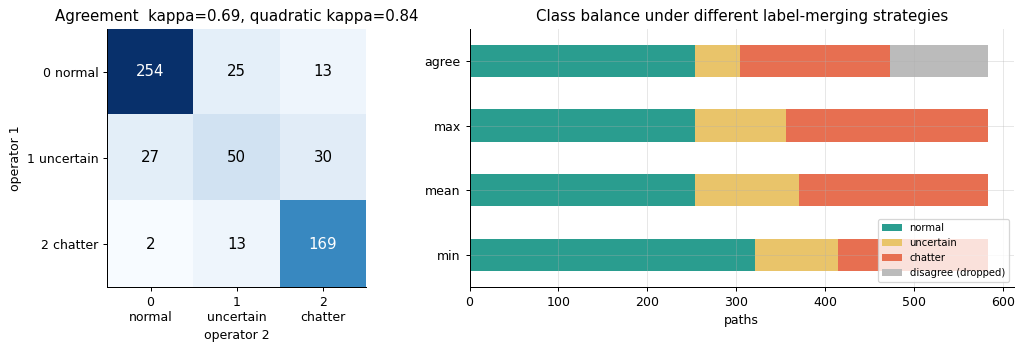

Exact agreement: 81%   Opposite-extreme disagreements (0 vs 2): 15


In [8]:
ct = pd.crosstab(imi["chatter_op1"].astype(int), imi["chatter_op2"].astype(int))
k = cohen_kappa(imi["chatter_op1"], imi["chatter_op2"])
kq = cohen_kappa(imi["chatter_op1"], imi["chatter_op2"], weights="quadratic")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.imshow(ct.values, cmap="Blues")
for (i, j), v in np.ndenumerate(ct.values):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > 100 else "black", fontsize=12)
ticks = [f"{c}\n{CHATTER_LABELS[c]}" for c in ct.columns]
ax.set_xticks(range(3), ticks); ax.set_yticks(range(3), [t.replace("\n", " ") for t in ticks])
ax.set(xlabel="operator 2", ylabel="operator 1", title=f"Agreement  kappa={k:.2f}, quadratic kappa={kq:.2f}")
ax.grid(False)

strategies = {s: consensus(imi["chatter_op1"], imi["chatter_op2"], s).value_counts(dropna=False).sort_index()
              for s in ["min", "mean", "max", "agree"]}
df = pd.DataFrame(strategies).T.fillna(0)
df.columns = [CHATTER_LABELS.get(c, "disagree (dropped)") if pd.notna(c) else "disagree (dropped)" for c in df.columns]
df.plot.barh(stacked=True, ax=axes[1], color=[LABEL_COLORS[0], LABEL_COLORS[1], LABEL_COLORS[2], "#bbbbbb"])
axes[1].set(title="Class balance under different label-merging strategies", xlabel="paths")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
print(f"Exact agreement: {(imi.chatter_op1 == imi.chatter_op2).mean():.0%}   "
      f"Opposite-extreme disagreements (0 vs 2): {int(ct.loc[0, 2] + ct.loc[2, 0])}")

* Agreement is **substantial** (kappa of about 0.69; quadratic-weighted kappa of about 0.84). Almost all disagreements involve the "uncertain" class. The operators rarely give opposite extremes: 0 vs. 2 happens in 15 of 583 paths.
* The label is therefore **ordinal and noisy around class 1**. You have to decide how to use it:
  * `max`: pessimistic. It gives the most chatter-positive labels and suits a safety or alarm use case.
  * `agree`: keeps only paths where both operators agree. This gives cleaner labels on fewer paths.
  * Binary vs. 3-class: `mtcut.labels.to_binary(uncertain_as=...)` merges or drops class 1.
* The rest of this notebook uses `max`.

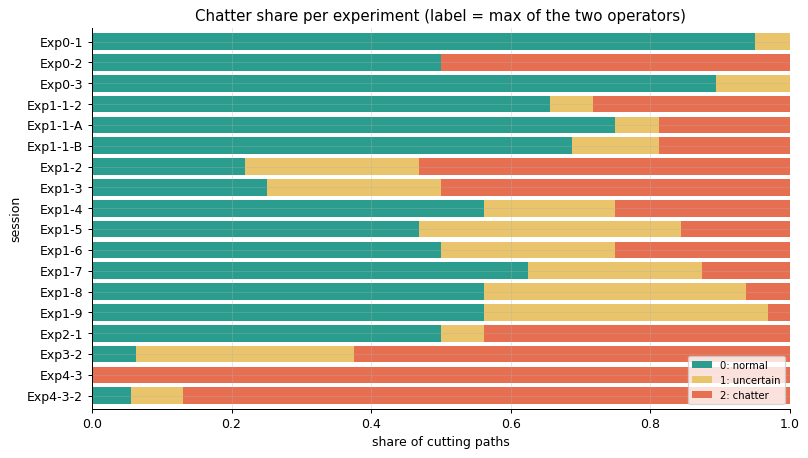

In [9]:
share = pd.crosstab(imi["session"], imi["chatter"].astype(int), normalize="index").reindex(design.index)
ax = share.plot.barh(stacked=True, figsize=(10, 5.5), color=[LABEL_COLORS[c] for c in share.columns], width=0.8)
ax.invert_yaxis(); ax.set_xlabel("share of cutting paths"); ax.set_xlim(0, 1)
ax.legend([f"{c}: {CHATTER_LABELS[c]}" for c in share.columns], loc="lower right", fontsize=8)
ax.set_title("Chatter share per experiment (label = max of the two operators)")
plt.show()

**This is the most important plot for designing experiments.** The chatter rate varies enormously between sessions. In `Exp4-3`, every path is chatter, while `Exp0-1` and `Exp0-3` have none. A random split over *windows* or *paths* lets a model learn to recognize the session (its tool, material, gain and room acoustics) instead of chatter. **Split by session** (for example, `GroupKFold` on `session`), or hold out whole experiments.

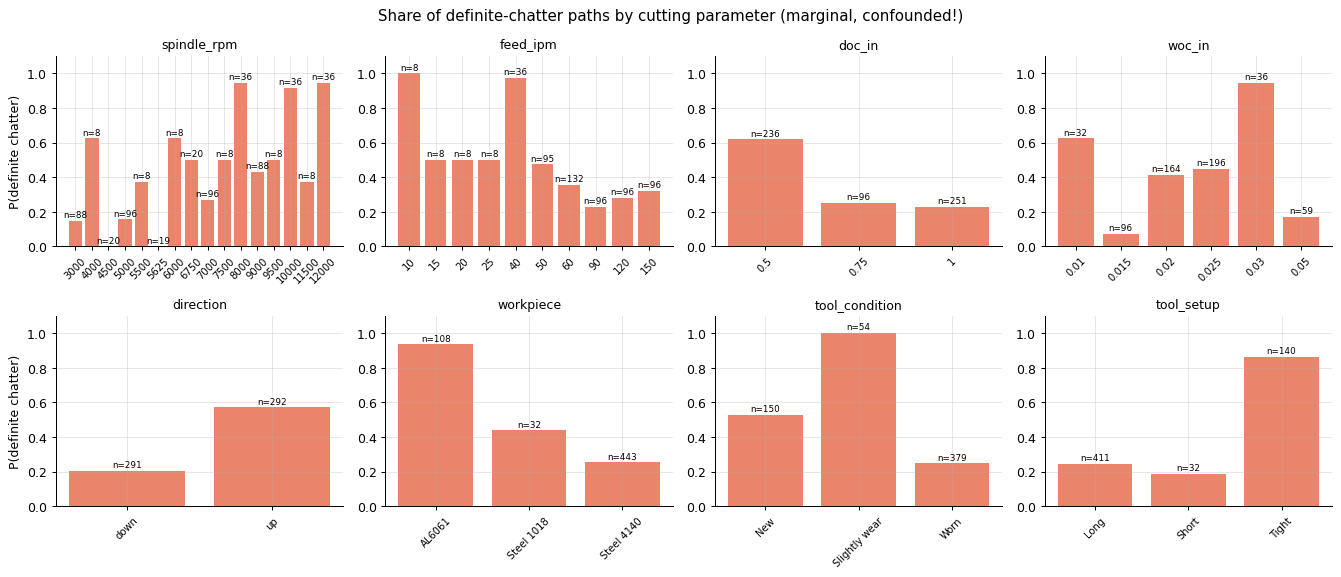

In [10]:
imi["is_chatter"] = (imi["chatter"] == 2).astype(float)
factors = ["spindle_rpm", "feed_ipm", "doc_in", "woc_in", "direction", "workpiece", "tool_condition", "tool_setup"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, f in zip(axes.flat, factors):
    g = imi.groupby(f)["is_chatter"].agg(["mean", "size"])
    ticks = [f"{i:g}" if isinstance(i, (int, float, np.number)) else str(i) for i in g.index]
    ax.bar(ticks, g["mean"], color="#e76f51", alpha=0.85)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.02, f"n={n}", ha="center", fontsize=7)
    ax.set_title(f, fontsize=10); ax.set_ylim(0, 1.1); ax.tick_params(axis="x", rotation=45, labelsize=8)
axes[0, 0].set_ylabel("P(definite chatter)"); axes[1, 0].set_ylabel("P(definite chatter)")
fig.suptitle("Share of definite-chatter paths by cutting parameter (marginal, confounded!)")
plt.tight_layout(); plt.show()

These marginal bars are **heavily confounded**. For example, DOC = 0.5 in looks the most chatter-prone only because every 1/4"-tool session (`Exp3-2`, `Exp4-3*`: aluminium, Tight setup, nearly all chatter) runs at DOC 0.5. In the same way, "AL6061", "Slightly wear" and "Tight" all mean "the `Exp4-3*` sessions".

The one clean comparison is **direction**. Paths come in up/down pairs with otherwise identical parameters, and up (conventional) milling chatters far more (about 57% vs. 21%).

To see real parameter effects, use the **controlled 3x3 grid** `Exp1-1-2` … `Exp1-9`. It has the same 1/2" tool, workpiece and setup, and varies only DOC x WOC, each with the same speed/feed sweep:

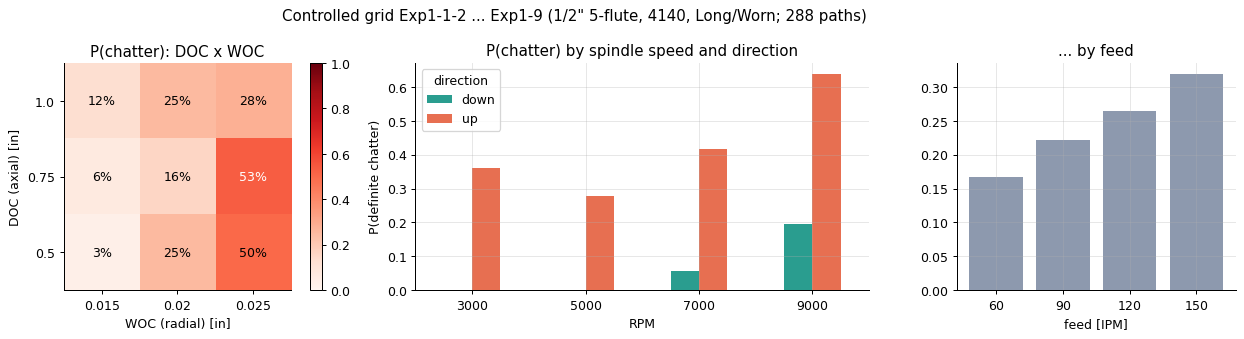

In [11]:
grid = imi[imi["session"].str.fullmatch(r"Exp1-(1-2|[2-9])")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.1, 1.3, 0.8]})
tab = grid.pivot_table(index="doc_in", columns="woc_in", values="is_chatter", aggfunc="mean")
im = axes[0].imshow(tab.values, cmap="Reds", vmin=0, vmax=1, origin="lower")
for (i, j), v in np.ndenumerate(tab.values):
    axes[0].text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.5 else "black")
axes[0].set_xticks(range(tab.shape[1]), tab.columns); axes[0].set_yticks(range(tab.shape[0]), tab.index)
axes[0].set(xlabel="WOC (radial) [in]", ylabel="DOC (axial) [in]", title="P(chatter): DOC x WOC"); axes[0].grid(False)
plt.colorbar(im, ax=axes[0], fraction=0.046)
rpm_dir = grid.pivot_table(index="spindle_rpm", columns="direction", values="is_chatter", aggfunc="mean")
rpm_dir.index = rpm_dir.index.astype(int)
rpm_dir.plot.bar(ax=axes[1], color=["#2a9d8f", "#e76f51"], rot=0)
axes[1].set(title="P(chatter) by spindle speed and direction", ylabel="P(definite chatter)", xlabel="RPM")
feed = grid.groupby("feed_ipm")["is_chatter"].mean()
axes[2].bar([f"{f:g}" for f in feed.index], feed.values, color="#8d99ae")
axes[2].set(title="... by feed", xlabel="feed [IPM]")
fig.suptitle("Controlled grid Exp1-1-2 ... Exp1-9 (1/2\" 5-flute, 4140, Long/Worn; 288 paths)")
plt.tight_layout(); plt.show()

Within the controlled grid:
* **Radial engagement (WOC) is the dominant factor**: chatter rises from about 7% at 0.015 in to about 44% at 0.025 in. Axial DOC barely matters at these depths.
* **Up milling** chatters in about 42% of paths. **Down milling almost never does** (about 6%).
* Chatter becomes more likely at the **highest spindle speed** (9000 RPM), consistent with the stability-lobe picture, where the stable depth of cut depends on speed.
* **Higher feed** (a larger chip load) also raises the chatter rate, from about 17% at 60 IPM to about 32% at 150 IPM.

These are exactly the conditions under which a detector must work. They also show that labels are strongly predictable from the cutting parameters. A model that gets the parameters (or can infer them from the sound) may shortcut through them.

## 5. What chatter looks and sounds like

Take two consecutive paths from `Exp1-2` that share **the same spindle speed, feed, DOC and WOC** and differ only in direction:
* path 0: **up** milling, both operators said **chatter (2, 2)**
* path 1: **down** milling, both operators said **normal (0, 0)**

First, the whole session: an RMS envelope for each sensor, with cutting paths shaded by label.

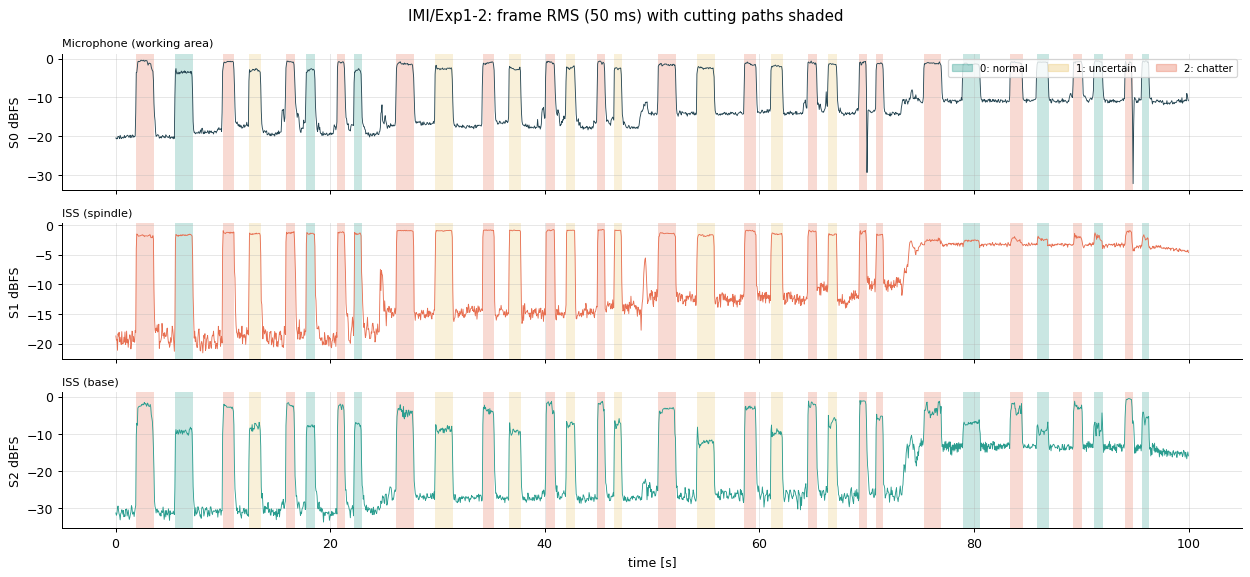

,path_idx,spindle_rpm,feed_ipm,direction,doc_in,woc_in,chatter_op1,chatter_op2
155,0,3000.0,60.0,up,0.75,0.025,2.0,2.0
156,1,3000.0,60.0,down,0.75,0.025,0.0,0.0
157,2,3000.0,90.0,up,0.75,0.025,2.0,2.0
158,3,3000.0,90.0,down,0.75,0.025,1.0,0.0
159,4,3000.0,120.0,up,0.75,0.025,2.0,2.0
160,5,3000.0,120.0,down,0.75,0.025,0.0,0.0


In [12]:
sess_name = "Exp1-2"
s = S[sess_name]
g = imi[imi["session"] == sess_name]
fig = plot_session_overview(s, g, label_col="chatter", figsize=(14, 6.5))
plt.show()
g[["path_idx", "spindle_rpm", "feed_ipm", "direction", "doc_in", "woc_in", "chatter_op1", "chatter_op2"]].head(6)

You can see the sweep structure: pairs of up/down paths at increasing feed and spindle speed. Chatter paths (red) are often, but **not always**, louder, so loudness alone is not a reliable detector.

### Listen
Both clips come from the spindle ISS (sensor 1), with the same gain. Chatter is the high-pitched "singing" tone on top of the normal cutting noise.

In [13]:
normal_i, chatter_i = 1, 0
for name, i in [("normal (path 1, down)", normal_i), ("chatter (path 0, up)", chatter_i)]:
    x = s.segment(1, i)
    print(name, f"{len(x) / SAMPLE_RATE:.2f} s")
    display(Audio(x, rate=SAMPLE_RATE, normalize=False))

normal (path 1, down) 1.65 s


chatter (path 0, up) 1.62 s


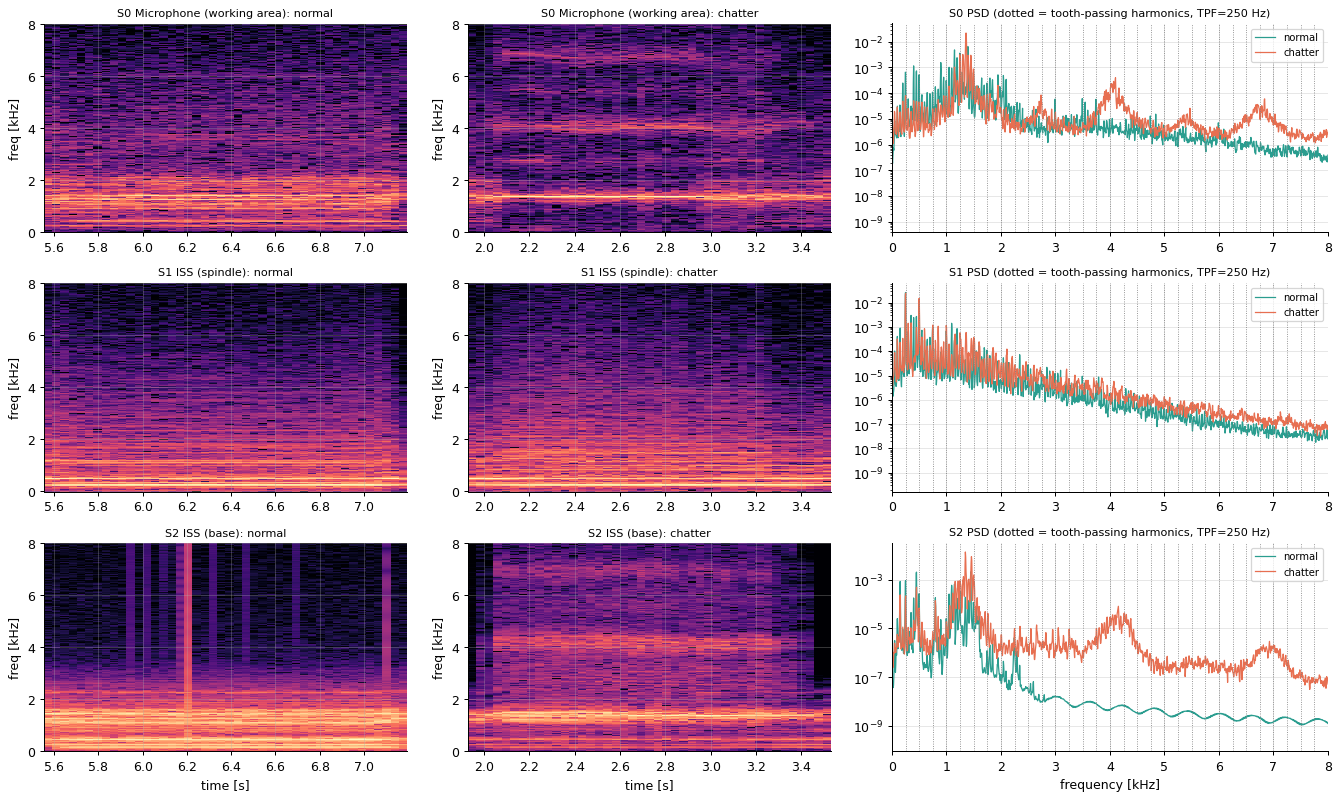

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9), gridspec_kw={"width_ratios": [1, 1, 1.2]})
row_n, row_c = g.iloc[normal_i], g.iloc[chatter_i]
tpf = row_c["tooth_passing_hz"]
for r, sensor in enumerate(s.sensors):
    xn, xc = s.segment(sensor, normal_i), s.segment(sensor, chatter_i)
    for c, (x, row, title) in enumerate([(xn, row_n, "normal"), (xc, row_c, "chatter")]):
        plot_spectrogram(axes[r, c], x, fmax=8000, t0=row["start"])
        axes[r, c].set_title(f"S{sensor} {SENSORS[sensor]}: {title}", fontsize=9)
    ax = axes[r, 2]
    for x, lab, col in [(xn, "normal", LABEL_COLORS[0]), (xc, "chatter", LABEL_COLORS[2])]:
        f, p = welch_psd(x)
        ax.semilogy(f / 1000, p, color=col, lw=1.0, label=lab)
    for h in tooth_passing_harmonics(tpf, 8000):
        ax.axvline(h / 1000, color="grey", ls=":", lw=0.7)
    ax.set_xlim(0, 8); ax.set_title(f"S{sensor} PSD (dotted = tooth-passing harmonics, TPF={tpf:.0f} Hz)", fontsize=9)
    ax.legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("time [s]" if ax is not axes[-1, 2] else "frequency [kHz]")
plt.tight_layout(); plt.show()

How to read this figure:
* **Tooth-passing frequency** (TPF) = RPM / 60 x flutes = 3000 / 60 x 5 = **250 Hz**. Normal milling is *forced* vibration, so its energy sits on the TPF harmonics (the dotted lines).
* **Chatter** is self-excited vibration near a structural natural frequency of the tool and holder. It appears as strong, persistent tonal lines ***between*** the TPF harmonics: the horizontal stripes in the chatter spectrograms and the extra peaks in the chatter PSDs.
* All three sensors see it, but with different clarity. The ISS sensors are mechanically coupled to the structure, while the microphone also picks up room noise.

## 6. A physics-informed view: energy off the tooth-passing harmonics

To check whether the effect above generalizes, we compute a simple indicator for every IMI path and sensor. The **off-harmonic energy ratio** is the share of 0.1-10 kHz energy that is *not* within ±2% of a TPF harmonic. `mtcut.features.harmonic_energy_ratio` implements it.

This loop reads every cutting path of every session once (about 1 minute). It also collects clipping and level statistics, which section 7 uses.

In [15]:
%%time
records, psds = [], []
for s_ in sessions:
    X = s_.load_all()                                   # (3, n) float32
    cut_mask = np.zeros(X.shape[1], dtype=bool)
    for _, r in seg[seg["session"] == s_.name].iterrows():
        i0, i1 = int(r["start"] * SAMPLE_RATE), int(r["end"] * SAMPLE_RATE)
        cut_mask[i0:i1] = True
        for k in s_.sensors:
            x = X[k, i0:i1]
            f, p = welch_psd(x)
            psds.append(p)
            records.append({
                "segment_id": r["segment_id"], "dataset": s_.dataset, "session": s_.name, "sensor": k,
                "chatter": r["chatter"], "rms_db": rms_db(x), "clip_frac": float(np.mean(np.abs(x) >= 32767 / 32768)),
                "off_harmonic": harmonic_energy_ratio(f, p, r["tooth_passing_hz"]) if pd.notna(r["tooth_passing_hz"]) else np.nan,
            })
    for k in s_.sensors:  # session-level: cutting vs idle level
        records.append({"session": s_.name, "dataset": s_.dataset, "sensor": k, "segment_id": None,
                        "cut_minus_idle_db": rms_db(X[k, cut_mask]) - rms_db(X[k, ~cut_mask]),
                        "clip_frac_all": float(np.mean(np.abs(X[k]) >= 32767 / 32768))})
FREQS = f
feat = pd.DataFrame(records)
seg_feat = feat[feat["segment_id"].notna()].reset_index(drop=True)
sess_feat = feat[feat["segment_id"].isna()].reset_index(drop=True)
PSD = np.array(psds)  # rows aligned with seg_feat
print(seg_feat.shape, PSD.shape)

(1791, 10) (1791, 4097)
CPU times: total: 11.6 s
Wall time: 12.2 s


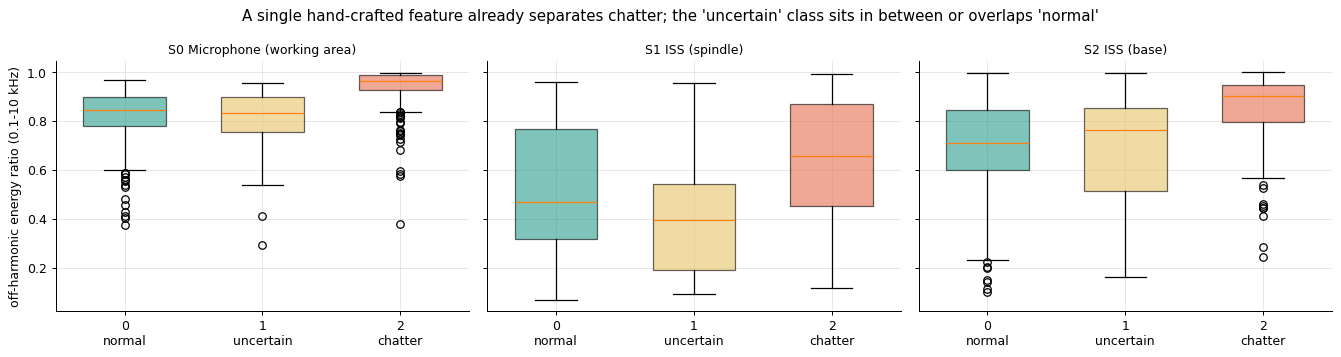

chatter   0.0   1.0   2.0
sensor                   
0        0.85  0.83  0.96
1        0.47  0.39  0.66
2        0.71  0.76  0.90


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
d = seg_feat[seg_feat["dataset"] == "IMI"]
for ax, k in zip(axes, [0, 1, 2]):
    data = [d[(d.sensor == k) & (d.chatter == c)]["off_harmonic"].dropna() for c in [0, 1, 2]]
    bp = ax.boxplot(data, labels=[f"{c}\n{CHATTER_LABELS[c]}" for c in [0, 1, 2]], patch_artist=True, widths=0.6)
    for patch, c in zip(bp["boxes"], [0, 1, 2]):
        patch.set_facecolor(LABEL_COLORS[c]); patch.set_alpha(0.6)
    ax.set_title(f"S{k} {SENSORS[k]}", fontsize=10)
axes[0].set_ylabel("off-harmonic energy ratio (0.1-10 kHz)")
fig.suptitle("A single hand-crafted feature already separates chatter; the 'uncertain' class sits in between or overlaps 'normal'")
plt.tight_layout(); plt.show()

print(d.groupby(["sensor", "chatter"])["off_harmonic"].median().unstack().round(2))

* A single physics-motivated number shifts clearly with the label on every sensor. This is a good sign that the labels are consistent with the signal.
* There is still **large overlap**. The TPF harmonics cover most of the band at high RPM with many flutes, and clipping (next section) smears energy across frequencies. A learned model (for example, a CNN on spectrograms, as in the paper) is expected to do much better, and this ratio is a useful **baseline feature**.
* Class 1 ("uncertain") behaves like a mixture. Treat it carefully.

## 7. Sensor comparison and data quality

### 7a. Which sensor "hears" cutting best?
Cutting-minus-idle level (dB) per session: how much louder the signal is while cutting than during the rest of the recording. Higher means cutting is easier to separate from idle noise.

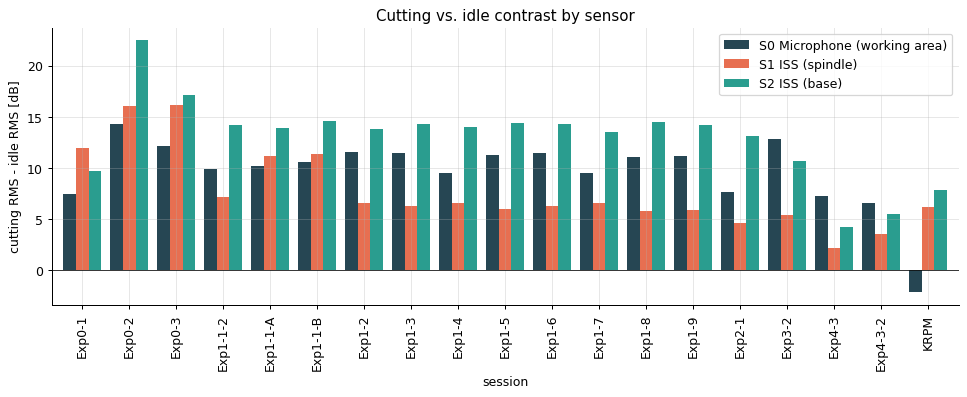

session,Exp0-1,Exp0-2,Exp0-3,Exp1-1-2,Exp1-1-A,Exp1-1-B,Exp1-2,Exp1-3,Exp1-4,Exp1-5,Exp1-6,Exp1-7,Exp1-8,Exp1-9,Exp2-1,Exp3-2,Exp4-3,Exp4-3-2,KRPM
S0 Microphone (working area),7.4,14.2,12.2,9.9,10.2,10.5,11.5,11.4,9.5,11.2,11.4,9.5,11.0,11.1,7.6,12.8,7.2,6.6,-2.2
S1 ISS (spindle),12.0,16.0,16.2,7.1,11.2,11.3,6.6,6.3,6.6,6.0,6.2,6.6,5.8,5.8,4.6,5.4,2.2,3.5,6.1
S2 ISS (base),9.7,22.5,17.2,14.1,13.9,14.6,13.8,14.3,13.9,14.4,14.3,13.5,14.5,14.2,13.1,10.6,4.2,5.5,7.8


In [17]:
cmi = sess_feat.pivot(index="session", columns="sensor", values="cut_minus_idle_db").reindex(sess["session"])
cmi.columns = [f"S{k} {SENSORS[k]}" for k in cmi.columns]
ax = cmi.plot.bar(figsize=(13, 4), color=[SENSOR_COLORS[k] for k in range(3)], width=0.8)
ax.set_ylabel("cutting RMS - idle RMS [dB]"); ax.axhline(0, color="k", lw=0.6)
ax.set_title("Cutting vs. idle contrast by sensor"); plt.show()
cmi.round(1).T

* On IMI, the **base ISS (S2)** usually gives the strongest cutting-vs-idle contrast with the 1/2" tool. The **spindle ISS (S1)** contrast is small because the spindle itself is loud even when not cutting.
* On **KRPM**, the working-area microphone is actually *quieter* while cutting than during idle. The factory background noise dominates it. The ISS sensors, being contact sensors, are much more robust to that.

### 7b. Clipping ⚠️
The IMI recordings were made with a high input gain. Here we count the fraction of samples at full scale (±32767).

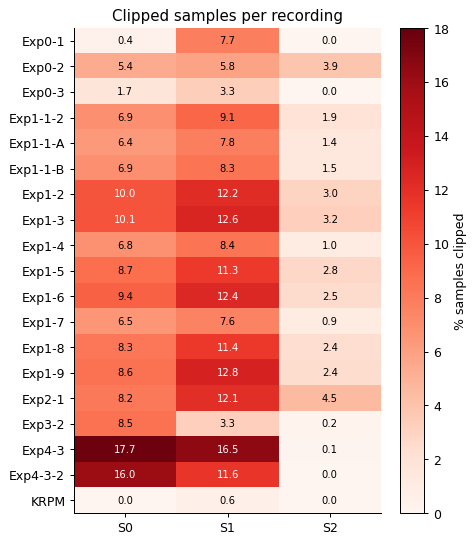

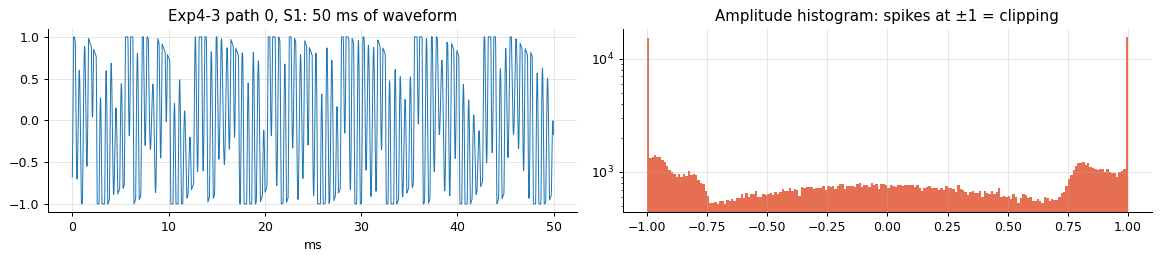

In [18]:
clip = sess_feat.pivot(index="session", columns="sensor", values="clip_frac_all").reindex(sess["session"]) * 100
fig, ax = plt.subplots(figsize=(5.5, 7))
im = ax.imshow(clip.values, cmap="Reds", aspect="auto", vmin=0, vmax=18)
for (i, j), v in np.ndenumerate(clip.values):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if v > 10 else "black")
ax.set_xticks(range(3), [f"S{k}" for k in range(3)]); ax.set_yticks(range(len(clip)), clip.index); ax.grid(False)
plt.colorbar(im, label="% samples clipped"); ax.set_title("Clipped samples per recording")
plt.show()

x = S["Exp4-3"].segment(1, 0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3))
t = np.arange(2400) / SAMPLE_RATE * 1000
axes[0].plot(t, x[24000:26400], lw=0.8); axes[0].set(title="Exp4-3 path 0, S1: 50 ms of waveform", xlabel="ms")
axes[1].hist(x, bins=200, color="#e76f51"); axes[1].set_yscale("log"); axes[1].set(title="Amplitude histogram: spikes at ±1 = clipping")
plt.tight_layout(); plt.show()

* **Up to about 17% of samples are clipped** in some IMI sessions (worst: `Exp4-3*` and the Exp1 series on S0/S1). KRPM is almost clean.
* Clipping adds odd harmonics and broadband distortion, so it changes exactly the spectral content that chatter detection relies on. Because clipping *correlates with loud cuts, and so with chatter*, it can act as a shortcut feature.
* It is also a **domain difference** between IMI and KRPM that a transfer or domain-adaptation model has to overcome.
* Mitigations to consider: per-window normalization, log-mel or PCEN front ends, simulating clipping on KRPM for augmentation, or reporting results per clipping level.

## 8. Lab vs. industry: IMI vs. KRPM

Average log-PSD over all cutting paths, per sensor. The IMI curves are split by label (KRPM has no labels).

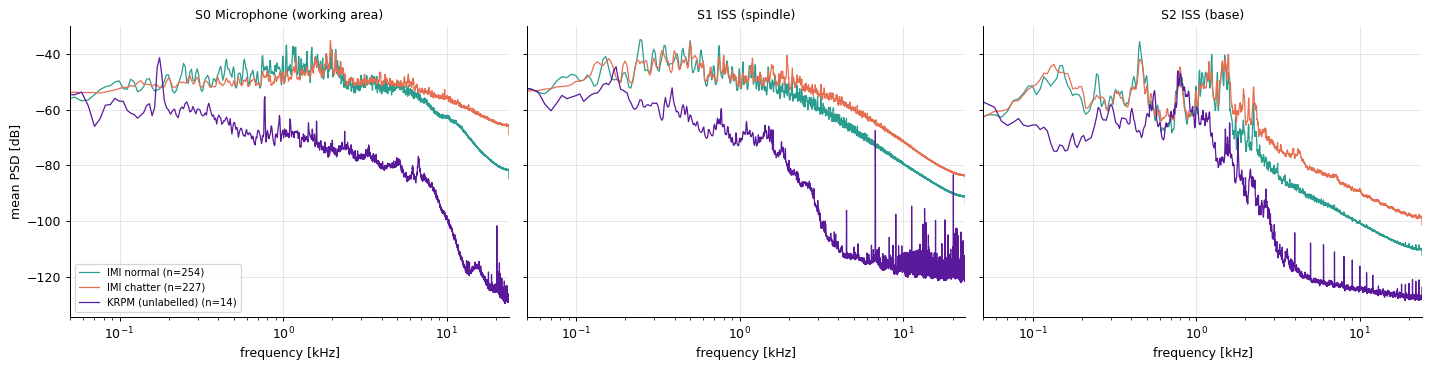

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
logP = 10 * np.log10(PSD + 1e-20)
for ax, k in zip(axes, [0, 1, 2]):
    m = seg_feat["sensor"] == k
    for lab, sel, col in [
        ("IMI normal", m & (seg_feat.dataset == "IMI") & (seg_feat.chatter == 0), LABEL_COLORS[0]),
        ("IMI chatter", m & (seg_feat.dataset == "IMI") & (seg_feat.chatter == 2), LABEL_COLORS[2]),
        ("KRPM (unlabelled)", m & (seg_feat.dataset == "KRPM"), "#5a189a"),
    ]:
        ax.plot(FREQS / 1000, logP[sel.to_numpy()].mean(0), color=col, lw=1, label=f"{lab} (n={sel.sum()})")
    ax.set_xscale("log"); ax.set_xlim(0.05, 24)
    ax.set_title(f"S{k} {SENSORS[k]}", fontsize=10); ax.set_xlabel("frequency [kHz]")
axes[0].set_ylabel("mean PSD [dB]"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

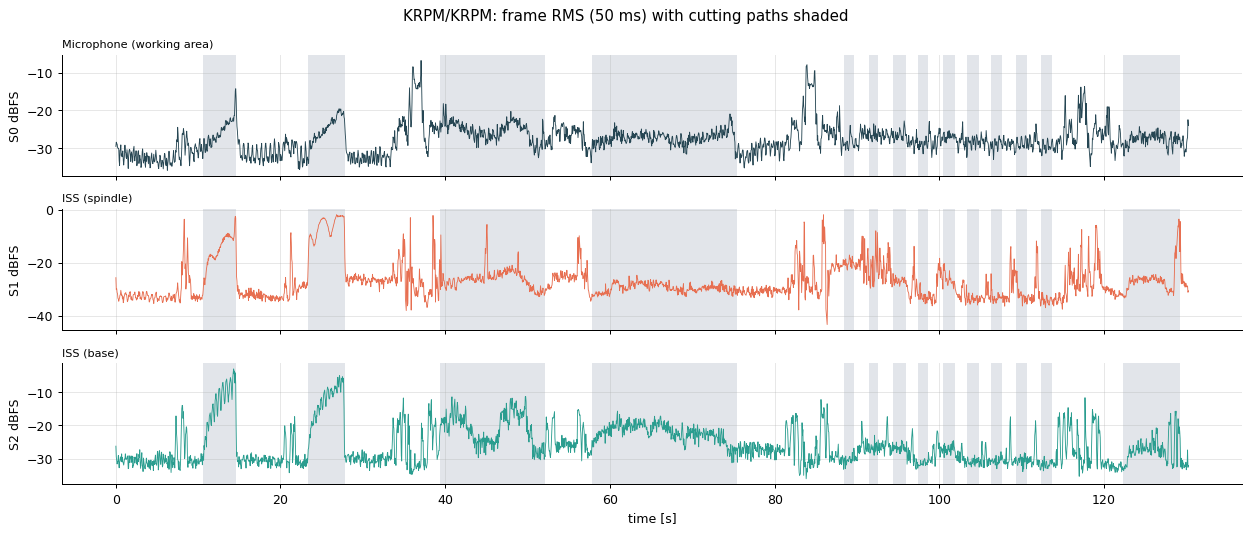

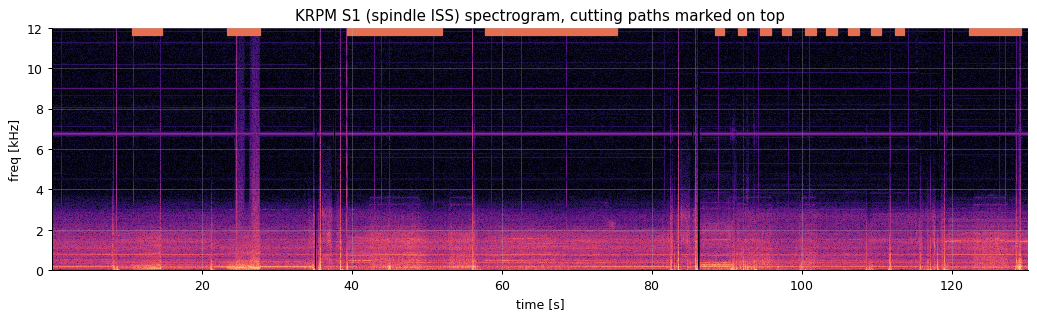

In [20]:
s_k = S["KRPM"]
fig = plot_session_overview(s_k, krpm, figsize=(14, 6))
plt.show()
fig, ax = plt.subplots(figsize=(14, 3.5))
mesh = plot_spectrogram(ax, s_k.load(1), fmax=12000, nperseg=4096)
for _, r in krpm.iterrows():
    ax.axvspan(r["start"], r["end"], ymin=0.97, ymax=1, color="#e76f51")
ax.set(title="KRPM S1 (spindle ISS) spectrogram, cutting paths marked on top", xlabel="time [s]")
plt.show()

* The spectral envelope differs a lot between the two machines (different spindle, tool, material, holder, room). This is the **domain shift** that the INDIN paper addresses with adversarial domain adaptation.
* KRPM overall levels are 10-20 dB lower (a different gain setting, hence almost no clipping). Its sensors carry little energy above about 3 kHz, while IMI's clipped signals spread energy up to 24 kHz. Note that the IMI *chatter* curves also sit above *normal* at high frequency. Part of that gap is likely clipping, not chatter.
* KRPM S1 has a **constant tone at about 6.7 kHz** for the whole recording (see the spectrogram), which is probably electrical interference. It is a narrow-band artefact that a model could latch onto.
* KRPM contains **facing and drilling**, not only end-milling, and a 4th axis. The paths are long, heterogeneous operations rather than a controlled sweep. With only 14 paths and no chatter labels, it suits **cutting / not-cutting detection** or unsupervised adaptation, not supervised chatter classification.

## 9. Takeaways for modelling

| Topic | Finding | Implication |
|---|---|---|
| Size | IMI: 583 paths (about 17 min of cutting x 3 sensors). KRPM: 14 paths (about 1 min). | Window the paths (for example, 2048 samples = 42.7 ms) to get enough examples. KRPM is a small target domain. |
| Labels | 2 operators, 0/1/2 scale, kappa of about 0.69. Disagreements mostly involve class 1. | Choose a merge strategy (`max` / `agree`) and binary vs. 3-class explicitly. Report which one you used. |
| Balance | With `max`: about 44% normal, 17% uncertain, 39% chatter over paths. | Moderately balanced at path level, but it varies hugely per session. |
| **Leakage** | Chatter rate ranges from 0% to 100% per session and is confounded with tool and material. | **Split by session / experiment**, never randomly by window. |
| Physics | Chatter = tonal energy between tooth-passing harmonics. Up milling and wide radial engagement (WOC) chatter more. | TPF-aware features or conditioning (`tooth_passing_hz` is in the segment table) can help. Beware of shortcuts through the cutting parameters. |
| Sensors | The ISS sensors are robust to ambient noise. The mic is weak in the factory. | Compare single-sensor vs. fused inputs. Expect S1/S2 to transfer better to KRPM. |
| **Quality** | Heavy clipping in IMI (up to 17% of samples). Almost none in KRPM. KRPM S1 has a constant 6.7 kHz tone. One overlapping interval pair. | Normalize and/or augment. Watch for clipping as a shortcut feature. Consider a notch filter or a band limit for KRPM. |
| Non-cutting audio | About 60% of every recording is idle or non-cutting. | A free "no cut" class, or negatives for a cutting-state detector. |

**Useful commands**
```bash
python scripts/validate_dataset.py      # integrity checks
python scripts/build_segment_index.py   # writes data/processed/{sessions,segments}.csv
```

**Next notebooks:** `02_windowing_and_features` (segment to fixed-length windows, log-mel / STFT features, session-grouped splits) → `03_baseline_models`.